In [1]:
import sys
import os
os.environ["NUMBA_THREADING_LAYER"]="workqueue"
os.environ["NUMBA_DISABLE_JIT"]="0"
os.environ["NUMBA_NUM_THREADS"]="1"
if 'google.colab' in sys.modules:
    !pip --quiet install open-atmos-jupyter-utils
    from open_atmos_jupyter_utils import pip_install_on_colab
    pip_install_on_colab('PyMPDATA')

In [2]:
%config InlineBackend.figure_formats = ['svg']
import numpy as np
from matplotlib import pyplot
from open_atmos_jupyter_utils import show_plot, show_anim
from PyMPDATA import ScalarField, Solver, Stepper, VectorField, Options, boundary_conditions

In [3]:
class ShallowWaterEquationsIntegratorWithBathymetry:
    def __init__(self, *, h_initial: np.ndarray, bathymetry: np.ndarray, options: Options = None):
        options = options or Options(nonoscillatory=True, infinite_gauge=True)
        self.bathymetry = bathymetry
        X, Y, grid = 0, 1, h_initial.shape
        stepper = Stepper(options=options, grid=grid)
        kwargs = {
            'boundary_conditions': [boundary_conditions.Periodic()] * len(grid),
            'halo': options.n_halo,
        }
        advectees = {
            "h": ScalarField(h_initial, **kwargs),
            "uh": ScalarField(np.zeros(grid), **kwargs),
            "vh": ScalarField(np.zeros(grid), **kwargs),
        }
        self.advector = VectorField((
                np.zeros((grid[X] + 1, grid[Y])),
                np.zeros((grid[X], grid[Y] + 1))
            ), **kwargs
        )
        self.solvers = { k: Solver(stepper, v, self.advector) for k, v in advectees.items() }

    def __getitem__(self, key):
        return self.solvers[key].advectee.get()

    def _apply_half_rhs(self, *, key, axis, g_times_dt_over_dxy):
        self[key][:] -= 0.5*g_times_dt_over_dxy*self['h']*np.gradient(self['h']-self.bathymetry,axis=axis)

    def _update_courant_numbers(self, *, axis, key, mask, dt_over_dxy):
        velocity = np.where(mask, np.nan, 0)
        momentum = self[key]
        np.divide(momentum, self['h'], where=mask, out=velocity)

        all = slice(None, None)
        all_but_last = slice(None, -1)
        all_but_first_and_last = slice(1, -1)

        velocity_at_cell_boundaries = velocity[(
            (all_but_last, all),
            (all, all_but_last),
        )[axis]] + np.diff(velocity, axis=axis) / 2
        courant_number = self.advector.get_component(axis)[(
            (all_but_first_and_last, all),
            (all, all_but_first_and_last)
        )[axis]]
        courant_number[:] = velocity_at_cell_boundaries * dt_over_dxy[axis]
        assert np.amax(np.abs(courant_number)) <= 1

    def __call__(self, *, nt: int, g: float, dt_over_dxy: tuple, outfreq: int, eps: float=1e-7):
        output = {k: [] for k in self.solvers.keys()}
        for it in range(nt + 1):
            if it != 0:
                mask = self['h'] > eps
                for axis, key in enumerate(("uh", "vh")):
                    self._update_courant_numbers(axis=axis, key=key, mask=mask, dt_over_dxy=dt_over_dxy)
                self.solvers["h"].advance(n_steps=1)
                for axis, key in enumerate(("uh", "vh")):
                    self._apply_half_rhs(key=key, axis=axis, g_times_dt_over_dxy=g * dt_over_dxy[axis])
                    self.solvers[key].advance(n_steps=1)
                    self._apply_half_rhs(key=key, axis=axis, g_times_dt_over_dxy=g * dt_over_dxy[axis])
            if it % outfreq == 0:
                for key in self.solvers.keys():
                    output[key].append(self[key].copy())
        return output

## Cel i założenia

Celem mojego projektu było zbadanie propagacji fali powodziowej powstałej wskutek przerwania wału przeciwpowodziowego na Odrze oraz określenie wpływu dodatkowej bariery na czas dotarcia i maksymalną wysokość fali uderzeniowej.

Do obliczeń wykorzystano model równań płytkiej wody 2D. Przyjęto początkowe spiętrzenie wody wynoszące 5 m oraz nierówności terenu w zakresie od -0,5 do 0,5 m. Punkt pomiarowy umieszczono 1020 m od wyrwy, a dodatkową barierę w odległości 800 m.

In [4]:
#| include: false
Lx, Ly = 1440, 600
T = 150
d_barier = 20

def symulacja(xs, ys, dt, h_barier=0):
    dx, dy = Lx/xs, Ly/ys
    bathymetry = np.ones((xs, ys))
    xi, yi = np.indices(bathymetry.shape)
    x, y = (xi+0.5)*dx-300, (yi+0.5)*dy

    bathymetry = -0.5*np.sin(2*np.pi*x/200)*np.cos(2*np.pi*y/150)
    bathymetry[x < 0] = 0
    bathymetry[(x >= -30) & (x < 0) & (np.abs(y-300) >= 30)] = -5
    bathymetry[(x >= 800) & (x < 800+d_barier)] -= h_barier

    h_initial = np.where(x < 0, np.maximum(bathymetry+5, 0.05), 0.05)

    outfreq = max(1, round(0.2/dt))

    output = ShallowWaterEquationsIntegratorWithBathymetry(
        h_initial=h_initial, bathymetry=bathymetry
    )(
        g=10, dt_over_dxy=(dt/dx, dt/dy), outfreq=outfreq, nt=round(T/dt), eps=0.1
        )

    ix = np.argmin(np.abs(x[:,0]-1020))
    iy = np.argmin(np.abs(y[0,:]-300))

    h = []
    for i in range(len(output['h'])):
        h.append(output['h'][i][ix,iy])
    h = np.array(h)
    t = np.where(h >= 0.15)[0]

    return t[0]*outfreq*dt

# Dobór kroku czasowego

Przeprowadzono symulacje dla różnych wartości kroku czasowego przy stałej rozdzielczości siatki. Porównywanym parametrem był czas dotarcia fali do punktu pomiarowego.

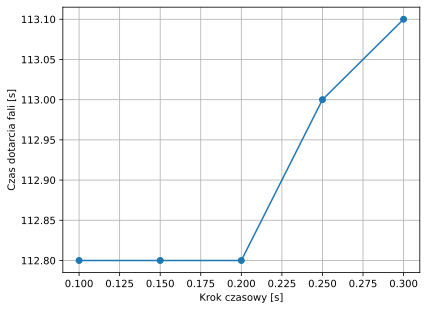

In [5]:
#| out-width: 70%
dt_ins = [0.3, 0.25, 0.2, 0.15, 0.1]
dt_outs = []

for dt in dt_ins:
    dt_outs.append(symulacja(60, 15, dt))

pyplot.plot(dt_ins, dt_outs, 'o-')
pyplot.xlabel('Krok czasowy [s]')
pyplot.ylabel('Czas dotarcia fali [s]')
pyplot.grid()
pyplot.show()

Dla kroków czasowych równych 0,2 s i mniejszych uzyskano jednakowy czas dotarcia fali. Ten krok czasowy przyjęto jako watość optymalną do dalszych obliczeń.

# Dobór kroku przestrzennego

Przy stałym kroku czasowym przeprowadzono symulacje dla różnych rozdzielczości siatki w kierunku X.

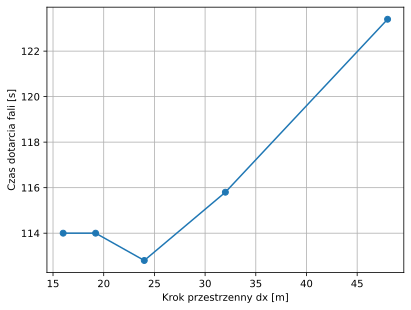

In [6]:
#| out-width: 70%
grid_ins = [30, 45, 60, 75, 90]
grid_outs = []

for xs in grid_ins:
    grid_outs.append(symulacja(xs, 15, 0.2))

pyplot.plot(Lx/np.array(grid_ins), grid_outs, 'o-')
pyplot.xlabel('Krok przestrzenny dx [m]')
pyplot.ylabel('Czas dotarcia fali [s]')
pyplot.grid()
pyplot.show()

Dla dwóch najgęstszych badanych siatek otrzymano jednakowy czas dotarcia fali. Do dalszych obliczeń wybrano siatkę o wymiarach 75 × 15 komórek.

# Symulacja końcowa

Przeprowadzono dwie symulacje trwające 150 s, przy ustalonym uprzednio kroku czasowym 0,2 s i kroku przestrzennym 19,2 m w kierunku X.

# Układ bez dodatkowej bariery

In [7]:
xs, ys = 75, 15
dt = 0.2
T = 150
h_barier = 0

Lx, Ly = 1440, 600

dx, dy = Lx/xs, Ly/ys
bathymetry= np.ones((xs, ys))
xi, yi = np.indices(bathymetry.shape)
x, y = (xi+0.5)*dx-300, (yi+0.5)*dy

bathymetry = -0.5*np.sin(2*np.pi*x/200)*np.cos(2*np.pi*y/150)
bathymetry[x < 0] = 0
bathymetry[(x >= -30) & (x < 0) & (np.abs(y-300) >= 30)] = -5
bathymetry[(x >= 800) & (x < 800+d_barier)] -= h_barier

h_initial = np.where(x < 0, np.maximum(bathymetry+5, 0.05), 0.05)

outfreq = max(1, round(0.2/dt))
nt = round(T/dt)

output = ShallowWaterEquationsIntegratorWithBathymetry(
    h_initial=h_initial, bathymetry=bathymetry
)(
    g=10, dt_over_dxy=(dt/dx, dt/dy), outfreq=outfreq, nt=nt, eps=0.1
)

ix = np.argmin(np.abs(x[:,0]-1020))
iy = np.argmin(np.abs(y[0,:]-300))

h = []
for i in range(len(output['h'])):
    h.append(output['h'][i][ix,iy])
h = np.array(h)

t = np.arange(len(h))*outfreq*dt
t_dotarcia = t[h >= 0.15]

print(f"Wysokość fali uderzeniowej: {np.max(h):.3f} m")
print(f"Czas dotarcia fali: {t_dotarcia[0]:.2f} s")

Wysokość fali uderzeniowej: 1.301 m
Czas dotarcia fali: 114.00 s



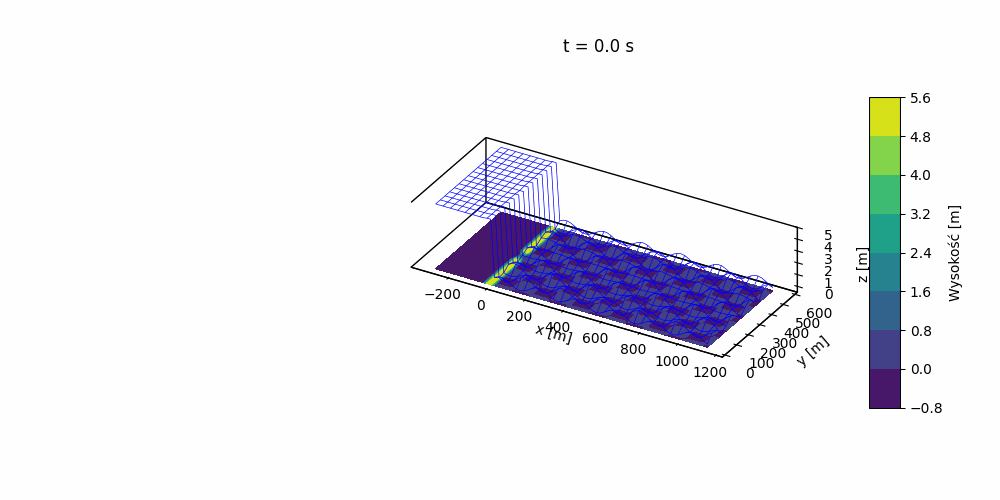

Button(description='tmpisfwy9e9.gif', style=ButtonStyle())

In [8]:
#| include: false
def plot(i, *, zlim=(-0.5, 5)):
    fig, ax = pyplot.subplots(figsize=(10, 5), subplot_kw={"projection": "3d"})
    ax.plot_wireframe(
        x, y, output['h'][i] - bathymetry,
        color='blue', linewidth=.5
    )
    ax.set_zlim(zlim)
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.pane.fill = False
        axis.pane.set_edgecolor('black')
        axis.pane.set_alpha(1)
    ax.grid(False)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.set_zlabel("z [m]")
    ax.set_proj_type('ortho')
    ax.set_box_aspect((Lx, Ly, 300))
    ax.set_title(f"t = {i*outfreq*dt:.1f} s")
    cnt = ax.contourf(x, y, -bathymetry, zdir='z', offset=zlim[0])
    pyplot.colorbar(cnt, pad=.1, aspect=10, fraction=.04, label='Wysokość [m]')
    return fig

show_anim(plot, range(0,len(output['h']),3))

### Układ z dodatkową barierą

Dla porównania wprowadzono barierę o wysokości 2,5 m, pozostawiając pozostałe parametry symulacji bez zmian.

In [9]:
xs, ys = 75, 15
dt = 0.2
T = 150
h_barier = 2.5

Lx, Ly = 1440, 600

dx, dy = Lx/xs, Ly/ys
bathymetry= np.ones((xs, ys))
xi, yi = np.indices(bathymetry.shape)
x, y = (xi+0.5)*dx-300, (yi+0.5)*dy

bathymetry = -0.5*np.sin(2*np.pi*x/200)*np.cos(2*np.pi*y/150)
bathymetry[x < 0] = 0
bathymetry[(x >= -30) & (x < 0) & (np.abs(y-300) >= 30)] = -5
bathymetry[(x >= 800) & (x < 800+d_barier)] -= h_barier

h_initial = np.where(x < 0, np.maximum(bathymetry+5, 0.05), 0.05)

outfreq = max(1, round(0.2/dt))
nt = round(T/dt)

output = ShallowWaterEquationsIntegratorWithBathymetry(
    h_initial=h_initial, bathymetry=bathymetry
)(
    g=10, dt_over_dxy=(dt/dx, dt/dy), outfreq=outfreq, nt=nt, eps=0.1
)

ix = np.argmin(np.abs(x[:,0]-1020))
iy = np.argmin(np.abs(y[0,:]-300))

h = []
for i in range(len(output['h'])):
    h.append(output['h'][i][ix,iy])
h = np.array(h)

t = np.arange(len(h))*outfreq*dt
t_dotarcia = t[h >= 0.15]

print(f"Wysokość fali uderzeniowej: {np.max(h):.3f} m")
print(f"Czas dotarcia fali: {t_dotarcia[0]:.2f} s")

Wysokość fali uderzeniowej: 1.162 m
Czas dotarcia fali: 115.40 s



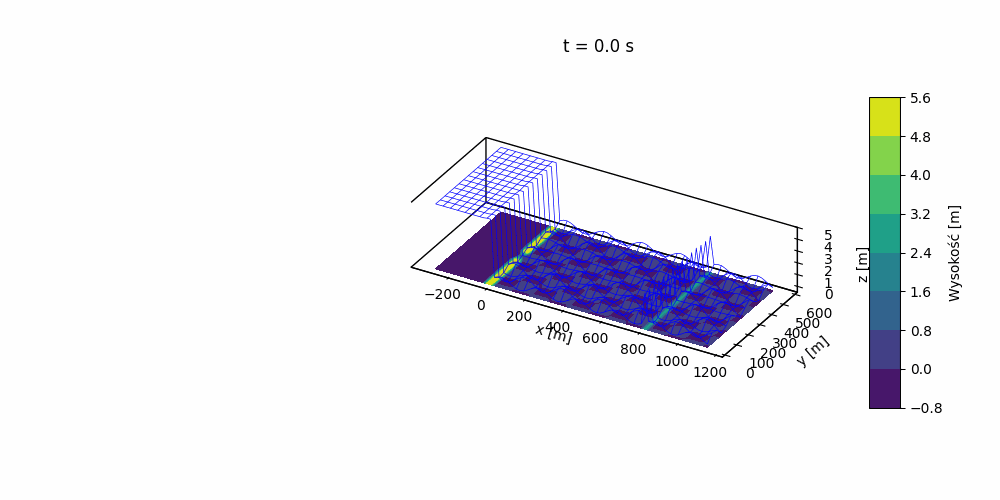

Button(description='tmp_a0fk5r6.gif', style=ButtonStyle())

In [10]:
#| include: false
def plot(i, *, zlim=(-0.5, 5)):
    fig, ax = pyplot.subplots(figsize=(10, 5), subplot_kw={"projection": "3d"})
    ax.plot_wireframe(
        x, y, output['h'][i] - bathymetry,
        color='blue', linewidth=.5
    )
    ax.set_zlim(zlim)
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.pane.fill = False
        axis.pane.set_edgecolor('black')
        axis.pane.set_alpha(1)
    ax.grid(False)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.set_zlabel("z [m]")
    ax.set_proj_type('ortho')
    ax.set_box_aspect((Lx, Ly, 300))
    ax.set_title(f"t = {i*outfreq*dt:.1f} s")
    cnt = ax.contourf(x, y, -bathymetry, zdir='z', offset=zlim[0])
    pyplot.colorbar(cnt, pad=.1, aspect=10, fraction=.04, label='Wysokość [m]')
    return fig

show_anim(plot, range(0,len(output['h']),3))

## Wnioski

Zastosowanie dodatkowej bariery opóźniło dotarcie fali do punktu pomiarowego o 1,4 s oraz zmniejszyło wysokość tafli uderzeniowej o 13,9 cm.

Uzyskane wyniki mają charakter przybliżony ze względu na ograniczoną rozdzielczość siatki, uproszczone ukształtowanie terenu oraz nieuwzględnienie tarcia wody o podłoże.